# ABO Dataset Pre-processing

In [ ]:
#Importing the necessary python libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

import tarfile
import gzip
import json

In [5]:
import tarfile
from pathlib import Path

#Find the ABO listings archive and check the content
archive_path = Path("abo-listings.tar")

print("Archive found:", archive_path.exists())

with tarfile.open(archive_path, "r") as tar:
    files = tar.getnames()

    print("Number of entries:", len(files))
    print("\nFirst 15 entries:")

    for file in files[:15]:
        print(file)

Archive found: True
Number of entries: 20

First 15 entries:
LICENSE-CC-BY-4.0.txt
listings
listings/README.md
listings/metadata
listings/metadata/listings_7.json.gz
listings/metadata/listings_4.json.gz
listings/metadata/listings_2.json.gz
listings/metadata/listings_c.json.gz
listings/metadata/listings_6.json.gz
listings/metadata/listings_0.json.gz
listings/metadata/listings_9.json.gz
listings/metadata/listings_e.json.gz
listings/metadata/listings_1.json.gz
listings/metadata/listings_5.json.gz
listings/metadata/listings_3.json.gz


In [6]:
import tarfile
import gzip
import json

with tarfile.open("abo-listings.tar", "r") as tar:

    # Look for the product metadata files
    metadata_files = [
        member for member in tar.getmembers()
        if member.name.startswith("listings/metadata/")
        and member.name.endswith(".json.gz")
    ]

    print("Number of metadata files:", len(metadata_files))

    file = tar.extractfile(metadata_files[0])
    
    # Open metadata file
    with gzip.open(file, "rt", encoding="utf-8") as f:
        first_product = json.loads(f.readline())

print("\nProduct fields:")
print(list(first_product.keys()))

print("\nExample product:")
print(json.dumps(first_product, indent=2, ensure_ascii=False)[:3000])

Number of metadata files: 16

Product fields:
['brand', 'bullet_point', 'color', 'fabric_type', 'item_id', 'item_name', 'item_weight', 'model_name', 'model_number', 'product_type', 'style', 'main_image_id', 'other_image_id', 'color_code', 'country', 'marketplace', 'domain_name']

Example product:
{
  "brand": [
    {
      "language_tag": "fr_FR",
      "value": "Amazon Essentials"
    }
  ],
  "bullet_point": [
    {
      "language_tag": "fr_FR",
      "value": "Plat classique et polyvalent conçu pour un usage quotidien et un ajustement supérieur."
    },
    {
      "language_tag": "fr_FR",
      "value": "Silhouette raffinée inspirée des mocassins avec couture propre. Dessus en cuir synthétique doux avec bords repliés non abrasifs."
    },
    {
      "language_tag": "fr_FR",
      "value": "Doublure en cuir véritable avec technologie de confort « Heel-Pillow » ; doublure en faux daim pour plus de confort et de respirabilité."
    },
    {
      "language_tag": "fr_FR",
      "valu

In [ ]:
# Check the essential fields of the first product

fields = [
    "item_id",
    "item_name",
    "bullet_point",
    "main_image_id",
    "other_image_id"
]

for field in fields:
    print(f"\n{field}:")
    print(str(first_product.get(field))[:500])


item_id:
B07NQ437BB

item_name:
[{'language_tag': 'fr_FR', 'value': 'Amazon Essentials Manny Footwear, Peau, 11 M US'}]

bullet_point:
[{'language_tag': 'fr_FR', 'value': 'Plat classique et polyvalent conçu pour un usage quotidien et un ajustement supérieur.'}, {'language_tag': 'fr_FR', 'value': 'Silhouette raffinée inspirée des mocassins avec couture propre. Dessus en cuir synthétique doux avec bords repliés non abrasifs.'}, {'language_tag': 'fr_FR', 'value': 'Doublure en cuir véritable avec technologie de confort « Heel-Pillow » ; doublure en faux daim pour plus de confort et de respirabilité.'}, {'language_tag': 'fr_FR', 'va

main_image_id:
61fH9aTfMIL

other_image_id:
['71AymDrpuFL', '61qXoMZjStL', '61qDo19NgzL', '61h3BqlKrNL', '61QPaJdIxaL', '71g+H66qBML', '61-Zjl2vLzL']


In [9]:
def extract_text(entries, language="en"):
    """Extract English text."""

    if not isinstance(entries, list):
        return ""

    values = []

    for entry in entries:
        if not isinstance(entry, dict):
            continue

        lang = entry.get("language_tag", "")
        value = entry.get("value", "")

        if lang.lower().startswith(language) and isinstance(value, str):
            if value.strip():
                values.append(value.strip())

    return " ".join(values)


# Test the function with the first product
product_id = first_product.get("item_id")
product_name = extract_text(first_product.get("item_name", []))
product_features = extract_text(first_product.get("bullet_point", []))
image_id = first_product.get("main_image_id")

print("Product ID:", product_id)
print("Product name:", product_name)
print("Product features:", product_features[:500])
print("Main image ID:", image_id)

Product ID: B07NQ437BB
Product name: 
Product features: 
Main image ID: 61fH9aTfMIL


In [ ]:
# Search for English text product
english_product = None

with tarfile.open("abo-listings.tar", "r") as tar:
    for member in metadata_files:
        file = tar.extractfile(member)

        with gzip.open(file, "rt", encoding="utf-8") as f:
            for line in f:
                product = json.loads(line)

                name = extract_text(product.get("item_name", []))
                features = extract_text(product.get("bullet_point", []))

                if name and features:
                    english_product = product
                    break

        if english_product is not None:
            break

if english_product is not None:
    print("Product ID:", english_product.get("item_id"))
    print("Product name:", extract_text(english_product.get("item_name", [])))
    print("Product features:",
          extract_text(english_product.get("bullet_point", []))[:500])
    print("Main image ID:", english_product.get("main_image_id"))
else:
    print("No product with English name and features found.")

Product ID: B0857LSVB7
Product name: Amazon Brand - Solimo Designer Lion UV Printed Soft Back Case Mobile Cover for Samsung Galaxy J2 Ace
Product features: Snug fit for Samsung Galaxy J2 Ace, with perfect cut-outs for volume buttons, audio and charging ports Compatible with Samsung Galaxy J2 Ace Easy to put & take off with perfect cutouts for volume buttons, audio & charging ports. Stylish design and appearance, express your unique personality. Extreme precision design allows easy access to all buttons and ports while featuring raised bezel to life screen and camera off flat surface.
Main image ID: 81-DuD5XzmL


In [ ]:
import pandas as pd
import tarfile
import gzip
import json

products = []

with tarfile.open("abo-listings.tar", "r") as tar:

    for member in metadata_files:
        file = tar.extractfile(member)

        with gzip.open(file, "rt", encoding="utf-8") as f:

            for line in f:
                product = json.loads(line)

                product_id = product.get("item_id")
                name = extract_text(product.get("item_name", []))
                features = extract_text(product.get("bullet_point", []))
                image_id = product.get("main_image_id")

                # Join the product and description names
                description = " ".join(
                    part for part in [name, features] if part
                ).strip()

                products.append({
                    "item_id": product_id,
                    "description": description,
                    "main_image_id": image_id
                })

df = pd.DataFrame(products)

print("Total product records:", len(df))
print("\nFirst five records:")
display(df.head())

Total product records: 147702

First five records:


,item_id,description,main_image_id
0,B07NQ437BB,,61fH9aTfMIL
1,B0857LSVB7,Amazon Brand - Solimo Designer Lion UV Printed...,81-DuD5XzmL
2,B07C5FF8QS,"AmazonBasics High Mileage Motor Oil, Synthetic...",81YCp3dcurL
3,B07K591232,,71EwvyC4A1L
4,B07TG425LX,Amazon Brand - Solimo Designer Semi Circle Tex...,71ZoXfUr-sL


In [13]:
print("Total records:", len(df))

print("Missing product IDs:",
      df["item_id"].isna().sum())

print("Empty descriptions:",
      df["description"].str.strip().eq("").sum())

print("Missing image IDs:",
      df["main_image_id"].isna().sum())

print("Duplicate product IDs:",
      df["item_id"].duplicated().sum())

Total records: 147702
Missing product IDs: 0
Empty descriptions: 24963
Missing image IDs: 575
Duplicate product IDs: 2087


In [ ]:
# Leave the original DataFrame the same
df_clean = df.copy()

# Eliminate the products that have descriptions that are not used
df_clean = df_clean[
    df_clean["description"].notna()
    & df_clean["description"].str.strip().ne("")
]

# Eliminate the products that don't have a main image ID
df_clean = df_clean[
    df_clean["main_image_id"].notna()
    & df_clean["main_image_id"].astype(str).str.strip().ne("")
]

# Discard the same duplicate records
df_clean = df_clean.drop_duplicates()

print("Original records:", len(df))
print("Records after initial cleaning:", len(df_clean))
print("Records removed:", len(df) - len(df_clean))
print("Remaining duplicate product IDs:",
      df_clean["item_id"].duplicated().sum())

Original records: 147702
Records after initial cleaning: 122206
Records removed: 25496
Remaining duplicate product IDs: 652


In [15]:
# Find products that still have duplicate IDs
duplicates = df_clean[
    df_clean.duplicated(subset="item_id", keep=False)
].sort_values("item_id")

print("Rows with duplicate product IDs:", len(duplicates))
print("Unique product IDs affected:", duplicates["item_id"].nunique())

# Display the first 10 duplicate records
display(duplicates.head(10))

Rows with duplicate product IDs: 1285
Unique product IDs affected: 633


,item_id,description,main_image_id
91509,B000GWJZPS,Pinzon Hemstitch 400-Thread-Count 100 Percent ...,61KXh-+pFYL
11974,B000GWJZPS,Pinzon 400-Thread-Count Hemstitch Egyptian Cot...,91Akl1oo8hL
126338,B000ON030U,Pinzon Hemstitch 400-Thread-Count 100 Percent ...,717KxNq7PrL
47388,B000ON030U,Pinzon Hemstitch 400-Thread-Count 100 Percent ...,71dxkG6bZPL
50973,B0015MN8KG,Amazon Essentials Platinum Plated Sterling Sil...,71UszmFEevL
117991,B0015MN8KG,Amazon Essentials Platinum Plated Sterling Sil...,710Ny5F0peL
50429,B0015MSD2O,Amazon Essentials Platinum Plated Sterling Sil...,61IdZ8R33uL
67691,B0015MSD2O,Amazon Essentials Platinum Plated Sterling Sil...,710OSAy3O8L
112879,B00198TT04,10k White Gold Calla Lily Diamond Pendant Neck...,71y2lB6zccL
34543,B00198TT04,10k White Gold Calla Lily Diamond Pendant Neck...,71QZhTw0oCL


In [ ]:
# Use the copy of the dataset that has been cleaned
df_unique = df_clean.copy()

# Work out the description length
df_unique["description_length"] = (
    df_unique["description"].str.len()
)

# Prefer the longest description for each product ID
df_unique = df_unique.sort_values(
    ["description_length", "item_id"],
    ascending=[False, True],
    kind="stable"
)

# Drop the duplicate records for each product ID
df_unique = df_unique.drop_duplicates(
    subset="item_id",
    keep="first"
)

# Eliminate the temporary column
df_unique = df_unique.drop(
    columns=["description_length"]
)

print("Records before resolving duplicates:", len(df_clean))
print("Records after resolving duplicates:", len(df_unique))
print("Remaining duplicate product IDs:",
      df_unique["item_id"].duplicated().sum())

display(df_unique.head())

Records before resolving duplicates: 122206
Records after resolving duplicates: 121554
Remaining duplicate product IDs: 0


,item_id,description,main_image_id
8827,B000HCR89W,"Classic Accessories 73922 Veranda Grill Cover,...",71NWZPIdX-L
7899,B000SMNJ6M,18k Yellow Gold Plated Sterling Silver Genuine...,81Khlw4DF7L
2182,B000W48HL8,Classic Accessories 70972 Veranda Patio Square...,71j9RmPJX3L
143174,B000W4AEE6,Classic Accessories 71982 Veranda Square Ottom...,71j9RmPJX3L
145692,B007XAKFUK,Classic Accessories 55-121-011501-00 Veranda R...,81sywArcBQL


In [ ]:
from pathlib import Path

image_folder = Path("abo-images-small")

#Look to see if the image folder exists 
print("Image folder exists:", image_folder.exists())

print("\nFirst 15 files or folders:")
for item in list(image_folder.iterdir())[:15]:
    print(item.name)

Image folder exists: True

First 15 files or folders:
LICENSE-CC-BY-4.0.txt
images


In [ ]:
from pathlib import Path

images_path = Path("abo-images-small/images")

#Look to see if the image folder exists 
print("Images folder exists:", images_path.exists())

print("\nFirst 15 files or folders:")

if images_path.exists():
    for item in list(images_path.iterdir())[:15]:
        print(item.name)

Images folder exists: True

First 15 files or folders:
small
README.md
metadata


In [ ]:
from pathlib import Path

small_path = Path("abo-images-small/images/small")

print("Small images folder exists:", small_path.exists())

print("\nFirst 15 files or folders:")

#Print the first 15 files or folders if a small path exists
if small_path.exists():
    for item in list(small_path.iterdir())[:15]:
        print(item.name)

Small images folder exists: True

First 15 files or folders:
61
0d
95
59
92
0c
66
3e
50
68
57
3b
6f
03
9b


In [ ]:
from pathlib import Path

small_path = Path("abo-images-small/images/small")

# Search for the first 10 image files from the subfolders
image_files = []

for file in small_path.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        image_files.append(file)

        if len(image_files) == 10:
            break

print("First 10 image files:")

for file in image_files:
    print(file)

First 10 image files:
abo-images-small/images/small/61/61cb7a56.jpg
abo-images-small/images/small/61/61c3c412.jpg
abo-images-small/images/small/61/61498c30.jpg
abo-images-small/images/small/61/61da5d32.jpg
abo-images-small/images/small/61/6129c2ce.jpg
abo-images-small/images/small/61/61596fbd.jpg
abo-images-small/images/small/61/61e28246.jpg
abo-images-small/images/small/61/614e8344.jpg
abo-images-small/images/small/61/61aa5c76.jpg
abo-images-small/images/small/61/6137c6ff.jpg


In [ ]:
from pathlib import Path

metadata_path = Path("abo-images-small/images/metadata")

print("Metadata folder exists:", metadata_path.exists())

print("\nFiles inside metadata folder:")

#Print the files that are in the metadata folder
if metadata_path.exists():
    for item in metadata_path.iterdir():
        print(item.name)

Metadata folder exists: True

Files inside metadata folder:
images.csv.gz


In [ ]:
import pandas as pd
from pathlib import Path

# Displays where the location is of the image metadata file
metadata_file = Path(
    "abo-images-small/images/metadata/images.csv.gz"
)

# Reads the compressed CSV file
images_df = pd.read_csv(metadata_file)

print("Total image metadata records:", len(images_df))

print("\nColumn names:")
print(images_df.columns.tolist())

print("\nFirst five records:")
display(images_df.head())

Total image metadata records: 398212

Column names:
['image_id', 'height', 'width', 'path']

First five records:


,image_id,height,width,path
0,010-mllS7JL,106,106,14/14fe8812.jpg
1,01dkn0Gyx0L,122,122,da/daab0cad.jpg
2,01sUPg0387L,111,111,d2/d2daaae9.jpg
3,1168jc-5r1L,186,186,3a/3a4e88e6.jpg
4,11RUV5Fs65L,30,500,d9/d91ab9cf.jpg


In [ ]:
from pathlib import Path

# Match each product's main image ID to image metadata
df_matched = df_unique.merge(
    images_df[["image_id", "path"]],
    left_on="main_image_id",
    right_on="image_id",
    how="left",
    validate="many_to_one"
)

# Generate the file paths for the images
image_root = Path("abo-images-small/images/small")

df_matched["image_path"] = df_matched["path"].apply(
    lambda p: str(image_root / p) if isinstance(p, str) else None
)

print("Total products:", len(df_matched))

print("Products with image metadata:",
      df_matched["path"].notna().sum())

print("Products without image metadata:",
      df_matched["path"].isna().sum())

display(df_matched.head())

Total products: 121554
Products with image metadata: 121554
Products without image metadata: 0


,item_id,description,main_image_id,image_id,path,image_path
0,B000HCR89W,"Classic Accessories 73922 Veranda Grill Cover,...",71NWZPIdX-L,71NWZPIdX-L,19/19c1e843.jpg,abo-images-small/images/small/19/19c1e843.jpg
1,B000SMNJ6M,18k Yellow Gold Plated Sterling Silver Genuine...,81Khlw4DF7L,81Khlw4DF7L,2b/2b60a1c7.jpg,abo-images-small/images/small/2b/2b60a1c7.jpg
2,B000W48HL8,Classic Accessories 70972 Veranda Patio Square...,71j9RmPJX3L,71j9RmPJX3L,01/0190eb0b.jpg,abo-images-small/images/small/01/0190eb0b.jpg
3,B000W4AEE6,Classic Accessories 71982 Veranda Square Ottom...,71j9RmPJX3L,71j9RmPJX3L,01/0190eb0b.jpg,abo-images-small/images/small/01/0190eb0b.jpg
4,B007XAKFUK,Classic Accessories 55-121-011501-00 Veranda R...,81sywArcBQL,81sywArcBQL,8b/8bf047dd.jpg,abo-images-small/images/small/8b/8bf047dd.jpg


In [ ]:
from pathlib import Path

# Look to see if the image files exist
df_matched["image_exists"] = df_matched["image_path"].apply(
    lambda p: Path(p).is_file() if p else False
)

print("Products with existing image files:",
      df_matched["image_exists"].sum())

print("Products with missing image files:",
      (~df_matched["image_exists"]).sum())

Products with existing image files: 121554
Products with missing image files: 0


In [ ]:
from pathlib import Path

# Store  products with the images that exist
df_final = df_matched[
    df_matched["image_exists"]
].copy()

# Choose the columns that are required for the coursework
df_final = df_final[
    ["item_id", "description", "main_image_id", "image_path"]
]

# Save the dataset that has been cleaned
output_folder = Path("processed")
output_folder.mkdir(exist_ok=True)

output_file = output_folder / "cleaned_products.csv"

df_final.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("File location:", output_file)
print("Total products:", len(df_final))
print("Duplicate product IDs:", df_final["item_id"].duplicated().sum())

Dataset saved successfully!
File location: processed/cleaned_products.csv
Total products: 121554
Duplicate product IDs: 0


# Exploratory Data Analysis

Description length statistics:
count    121554.000000
mean         75.017926
std          32.751339
min           1.000000
25%          65.000000
50%          83.000000
75%          87.000000
max         617.000000
Name: word_count, dtype: float64


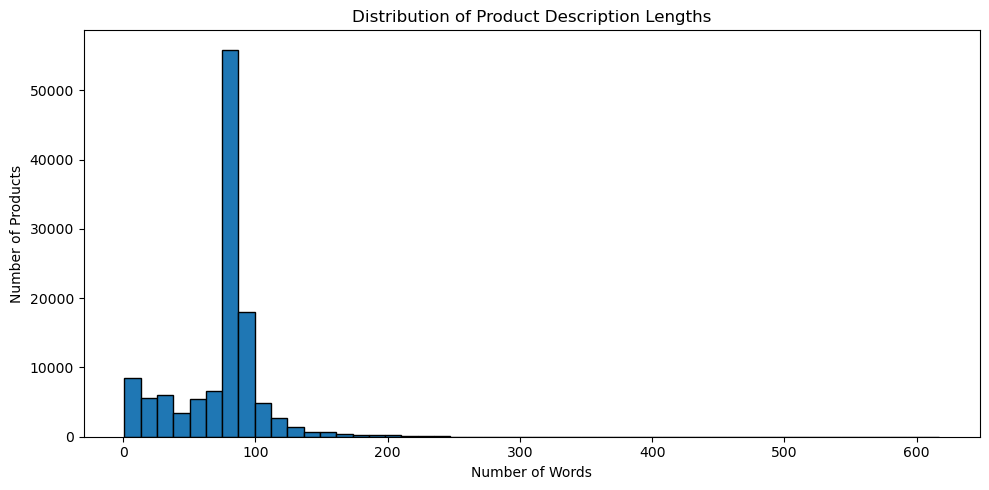

In [ ]:
import matplotlib.pyplot as plt

# Work out the number of words in the description
df_final["word_count"] = (
    df_final["description"].str.split().str.len()
)

# Show the summary statistics
print("Description length statistics:")
print(df_final["word_count"].describe())

# Design a histogram
plt.figure(figsize=(10, 5))

plt.hist(
    df_final["word_count"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Product Description Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

In [ ]:
# Count the descriptions under 5 words
print("Descriptions under 5 words:",
      (df_final["word_count"] < 5).sum())

print("Descriptions under 10 words:",
      (df_final["word_count"] < 10).sum())

# Illustrate the examples
display(
    df_final[df_final["word_count"] < 5][
        ["item_id", "description", "word_count"]
    ].head(10)
)

Descriptions under 5 words: 941
Descriptions under 10 words: 5331


,item_id,description,word_count
115809,B06Y15K7TH,[Find] Amazon Collection siruba-mekkikuriagara...,4
118465,B07D5M9R47,AmazonBasics Classroom ブロック収納キャビネットキャスター付き、4キュービ,3
118468,B07F2HR7YP,Ravenna Home 320-DS-C133-708-1-Upholstery: Chair,4
118584,B08834QP1L,AmazonBasics Light-Weight Microfiber Pillowcases,4
118613,B076KSJ5JQ,"AmazonBasics Mattress Encasement, 140X200CM+12""",4
118630,B07D5MHJ5J,AmazonBasics Single-Sided Wooden Bookディスプレイ、ブルー,4
118757,B076KS4R4D,"AmazonBasics Mattress Encasement, 90X200CM+12""",4
119181,B083V88R15,AmazonCommercial Multifuction Moisture Meter,4
119208,B01IVVEXZC,"AmazonBasics Pillowcase, Chocolate, 50x75x2",4
119209,B01IVVF1BC,"AmazonBasics Pillowcase, Chocolate, 80x80x2",4


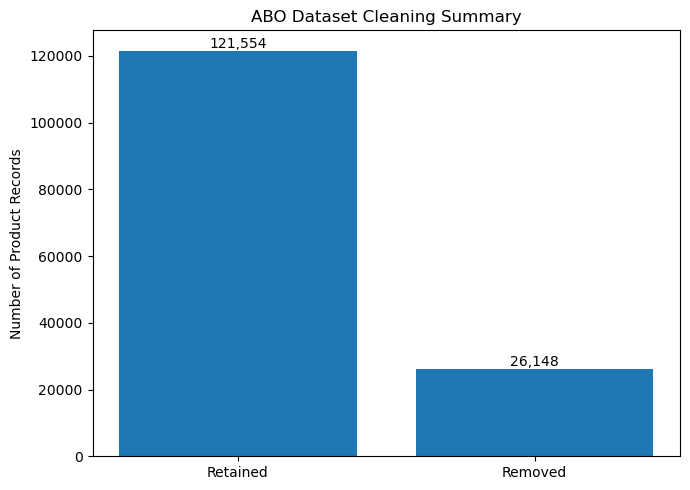

Original records: 147702
Retained records: 121554
Removed records: 26148


In [ ]:
import matplotlib.pyplot as plt

original_count = len(df)
cleaned_count = len(df_final)
removed_count = original_count - cleaned_count

#Find the values for the bar chart
labels = ["Retained", "Removed"]
counts = [cleaned_count, removed_count]

plt.figure(figsize=(7, 5))

bars = plt.bar(labels, counts)

plt.title("ABO Dataset Cleaning Summary")
plt.ylabel("Number of Product Records")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("processed/cleaning_summary.png", dpi=300)
plt.show()

print("Original records:", original_count)
print("Retained records:", cleaned_count)
print("Removed records:", removed_count)